# Figures of the EV_GU paper

Draws Figs. 2 to 9 of *What Graph Unlearning Cannot Erase: Physics-Induced Leakage of Cyberattack Information in
Electric Vehicle Charging Networks*. Fig. 1 is a drawing. The figures are written to `results/paper_figures/`.

The inputs are the PowerBench EVCS data (`DATA_DIR`) and the result folders that `scripts/run_paper.sh` and the
analysis scripts write under `results/`; see the README.

In [1]:
# Setup: paths, the shared style of fig_style.py, and the data of the voltage-only analysis (E9)
import pickle
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import fig_style as fs

ROOT = Path.cwd().resolve().parent        # the repository; this notebook lives in notebooks/
RESULTS = ROOT / 'results'
DATA_DIR = ROOT.parent / 'Source' / 'PB_data' / '3_EVCS Attacks'   # PowerBench EVCS data, the --data_dir of train.py
OUT = RESULTS / 'paper_figures'
OUT.mkdir(parents=True, exist_ok=True)

DATA = RESULTS / '2026-10-12_E9topo'      # scripts/compute_e9.py and compute_e9_joint.py
FIGB = RESULTS / '2026-10-12_figB'        # scripts/analysis_figB.py
TABLES = RESULTS / '2026-10-30_tables'    # scripts/make_tables.py
RE = RESULTS / '2026-10-15_E4E10'         # scripts/analysis_e4e10.py

fs.use()
FEEDERS = {f: fs.FEEDER[f] for f in ('34bus', '123bus')}
KEY_COLOR = 'black'                       # legend keys for line style or fill, which carry no color of their own

GML = {'34bus': DATA_DIR / '34_bus' / '34busEx.gml',
       '123bus': DATA_DIR / '123_bus' / '123busEx.gml'}
ROOT_BUS = {'34bus': 'sourcebus', '123bus': '150'}

STATION_COLORS, NOISE, TYPE_COLORS = fs.STATION, fs.NOISE, fs.ATTACK_TYPE
CAT_STYLE = {'no regulator': ('#1F5F8B', 'o'), 'regulator on the shared path': ('#2CA6A4', 's'),
             'shielded by a regulator': ('#EC6E66', '^')}

str_cols = {'bus': str, 'station_bus': str}
dist = pd.read_csv(DATA / 'e9_distance.csv', dtype=str_cols)
auc = pd.read_csv(DATA / 'e9_auc_all.csv', dtype=str_cols).merge(dist, on=['feeder', 'station_bus', 'bus'])
auc_type = pd.read_csv(DATA / 'e9_auc_type.csv', dtype=str_cols).merge(dist, on=['feeder', 'station_bus', 'bus'])
ldf = pd.read_csv(DATA / 'e9_lindistflow.csv', dtype=str_cols)
STATIONS = {f: list(dict.fromkeys(auc[auc.feeder == f].station_bus)) for f in FEEDERS}


def at_snr(df, snr):
    return df[df.snr_db.isna()] if snr is None else df[df.snr_db == snr]


def binned(df, edges=(0, 0.1, 0.4, 0.7, 0.95, 1.0001)):
    """Mean AUC and 95% CI in bins of the electrical distance."""
    # A bus that responds more than the station itself (R_ij > R_jj, upstream of the regulator in front of the
    # station) counts as d = 0 instead of dropping out of the bins
    cut = pd.cut(df.d_elec.clip(lower=0), edges, include_lowest=True, right=False)
    g = df.groupby(cut, observed=True).auc
    centers = [(i.left + min(i.right, 1.0)) / 2 for i in g.mean().index]
    return np.array(centers), g.mean().values, 1.96 * g.sem().fillna(0).values


REG_COLOR, EVCS_COLOR = 'red', 'green'           # voltage regulators and charging stations in the figures
REG_TEXT, EVCS_TEXT = '#1F5F8B', '#7B61B3'       # their names where red and green carry the AUC scale


def regulator_outputs(G, root):
    """The bus on the load side of every voltage regulator."""
    depth = nx.single_source_shortest_path_length(G, root)
    return {max((u, v), key=depth.get) for u, v, a in G.edges(data=True)
            if str(a.get('Label', '')).startswith('reg')}

## Figs. 2 and 3: charging power and bus voltage under the four attack types

In [2]:
FIG23_RC = {}                             # the style of Figs. 2 and 3, applied only to them
# ---- Config and data loading ----

# Times New Roman to match the paper
FIG23_RC['font.family'] = 'serif'
FIG23_RC['font.serif'] = ['Times New Roman']
FIG23_RC['mathtext.fontset'] = 'stix'

PKL_PATH = DATA_DIR / '34_bus' / 'EVCSAttacks_34.pkl'
OUT_DIR  = OUT
DAY_HOURS = 24.0   # each series spans one day; x-axis is hour of day

# EVCS station (power key) -> bus name (voltage key), inferred by rated power:
# 1 -> 814 (300 kW), 2 -> 890 (260 kW), 3 -> 852 (550 kW)
STATION_TO_BUS = {1: '814', 2: '890', 3: '852'}

# Per-type data source and selection rule. Edit 'station' / 'hour' freely.
#   mode 'visible' : sample with the largest |power deviation| (for the subtle Type 1)
#   mode 'inject'  : sample that relocates the demand spike to 'hour' (tall, no overshoot)
#   mode 'surge'   : like 'inject', but prefers the spike that most exceeds the normal peak
# Types 2/3/4 are injected at different hours so the four panels look clearly distinct.
TYPE_CONFIG = {
    'Type 1': {'station': 2, 'mode': 'visible'},
    'Type 2': {'station': 2, 'mode': 'inject', 'hour': 10},
    'Type 3': {'station': 2, 'mode': 'inject', 'hour': 16},
    'Type 4': {'station': 2, 'mode': 'surge',  'hour': 12},
}
NIL_SAMPLE_N = 0   # which Nil sample serves as the Normal baseline

ATTACK_TYPES  = ['Type 1', 'Type 2', 'Type 3', 'Type 4']
SUBFIG_LABELS = ['(a)', '(b)', '(c)', '(d)']
COLORS = {
    'Normal': '#2ecc71',
    'Type 1': '#e74c3c',
    'Type 2': '#3498db',
    'Type 3': '#9b59b6',
    'Type 4': '#f39c12',
}

# Font sizes (kept large on purpose)
FS_LABEL  = 26
FS_TITLE  = 26
FS_LEGEND = 22
FS_TICK   = 24


def to_1d(x):
    """Flatten a nested list / ndarray to a 1-D float array."""
    return np.asarray(x, dtype=float).ravel()


def hours_axis(n):
    """Map sample indices of a one-day series to the hour of day [0, 24)."""
    return np.arange(n) * DAY_HOURS / n


with open(PKL_PATH, 'rb') as fh:
    data = pickle.load(fh)

samples_by_type = {}
for s in data:
    samples_by_type.setdefault(s['Attack Type'], []).append(s)

nil_sample = samples_by_type['Nil'][NIL_SAMPLE_N]


def _power(sample, station):
    return to_1d(sample['EVCS power series'][station])


def _visibility(sample, station):
    """Peak |power deviation| from the baseline, normalized by the station peak."""
    base = _power(nil_sample, station)
    return np.max(np.abs(_power(sample, station) - base)) / max(base.max(), 1e-9)


def _inject_hour(sample, station):
    """Hour of day where the attack adds the most charging power."""
    a = _power(sample, station)
    return int(round(np.argmax(a - _power(nil_sample, station)) * DAY_HOURS / len(a)))


def _overshoot(sample, station):
    """How far the attacked peak exceeds the normal daily peak (kW)."""
    return _power(sample, station).max() - _power(nil_sample, station).max()


def resolve_source(attack_type, cfg):
    """Return (station_key, sample) following the per-type selection rule."""
    st  = cfg['station']
    tag = 'EVCS {}'.format(st)
    cands = [s for s in samples_by_type[attack_type] if s['Targeted Stations'] == [tag]]
    mode = cfg.get('mode', 'visible')
    if mode == 'visible':
        return st, max(cands, key=lambda s: _visibility(s, st))
    hour = cfg['hour']
    at_hour = [s for s in cands if _inject_hour(s, st) == hour] or cands
    if mode == 'surge':
        return st, max(at_hour, key=lambda s: (_overshoot(s, st), _visibility(s, st)))
    return st, max(at_hour, key=lambda s: _visibility(s, st))   # mode == 'inject'


# Resolve one shared source per type so the power and voltage figures stay aligned.
sources = {}
print('Resolved data sources (power and voltage share the same sample per type):')
for at in ATTACK_TYPES:
    st, att = resolve_source(at, TYPE_CONFIG[at])
    bus = STATION_TO_BUS[st]
    sources[at] = {'station': st, 'bus': bus, 'nil': nil_sample, 'att': att}
    print('  {}: Bus {}, idx={}, inject@{}h, overshoot={:+.1f} kW, peak dev={:.0f}% of station peak'
          .format(at, bus, att['Index'], _inject_hour(att, st),
                  _overshoot(att, st), 100 * _visibility(att, st)))

Resolved data sources (power and voltage share the same sample per type):
  Type 1: Bus 890, idx=579, inject@13h, overshoot=-0.0 kW, peak dev=5% of station peak
  Type 2: Bus 890, idx=851, inject@10h, overshoot=+0.0 kW, peak dev=99% of station peak
  Type 3: Bus 890, idx=1574, inject@16h, overshoot=+0.0 kW, peak dev=99% of station peak
  Type 4: Bus 890, idx=1946, inject@12h, overshoot=+4.8 kW, peak dev=52% of station peak


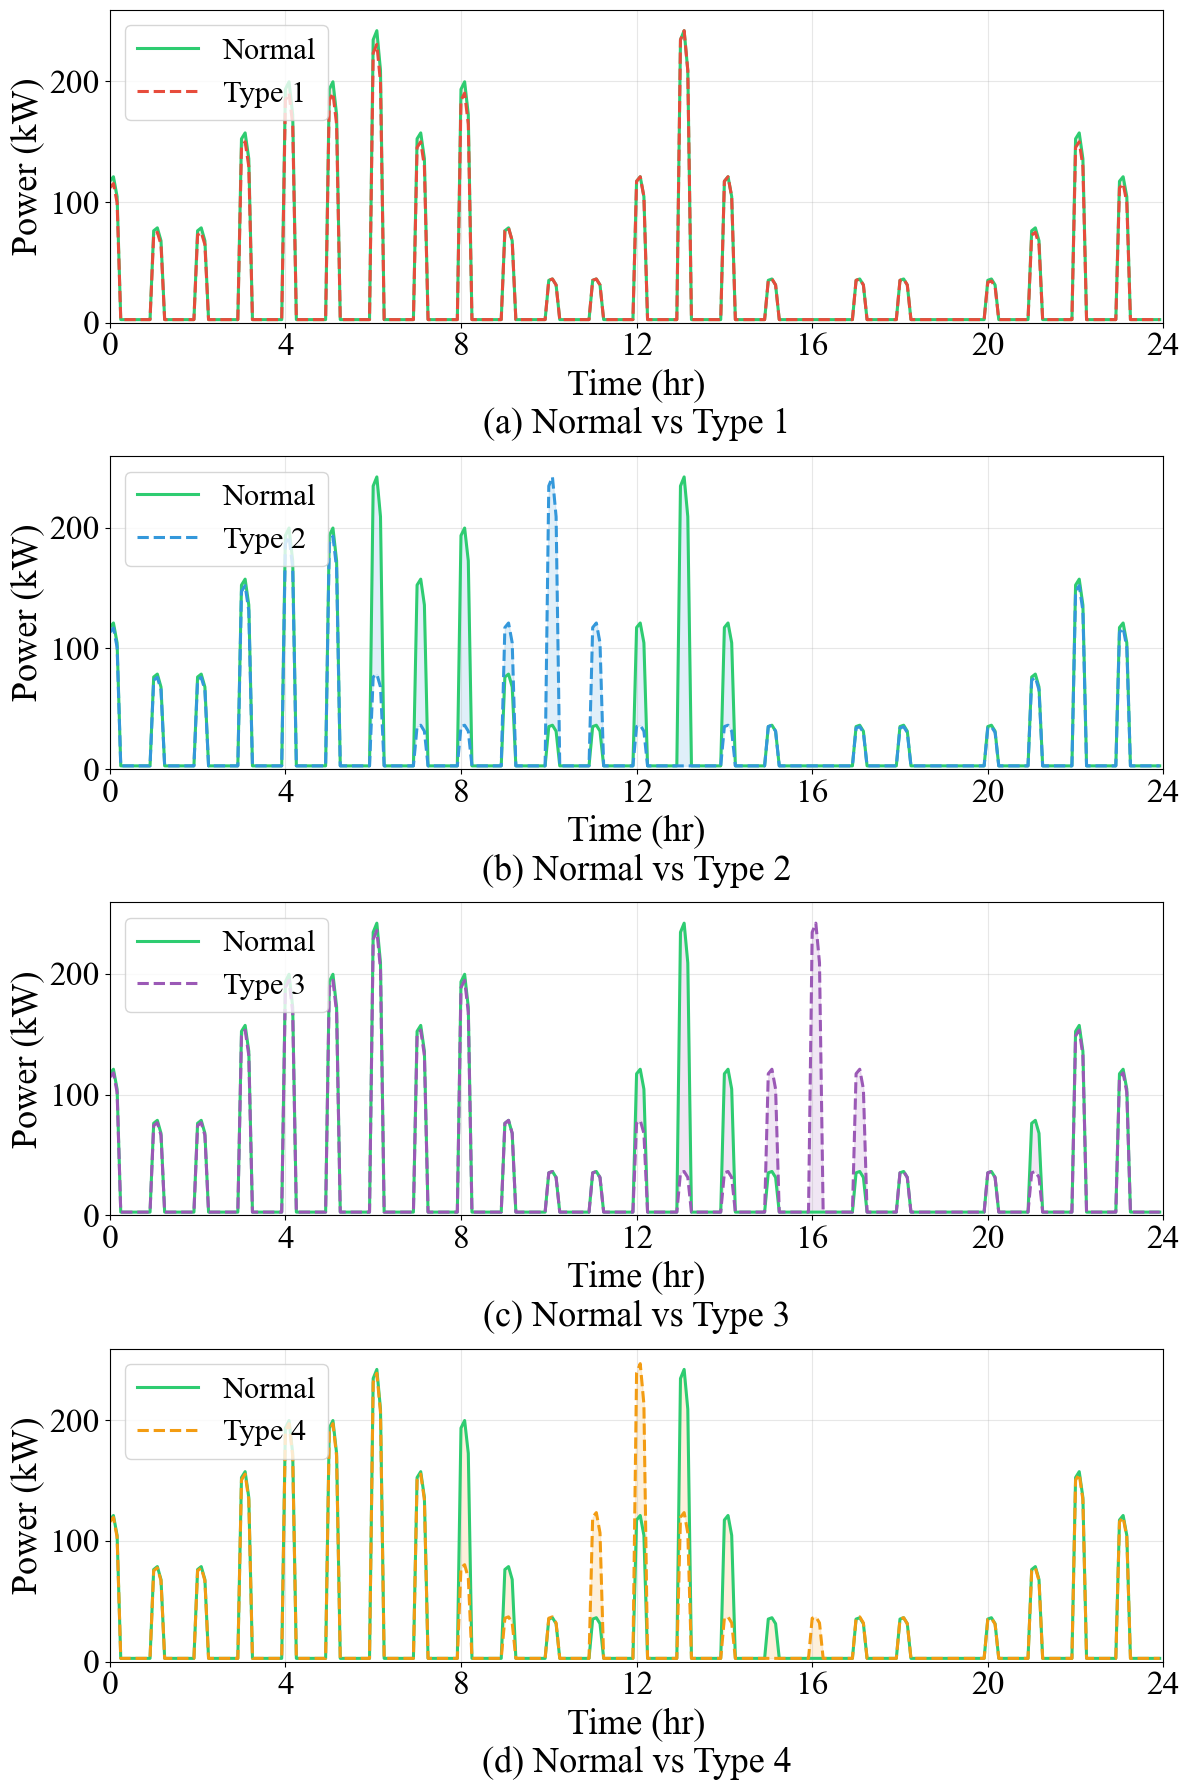

saved ITSG_power.pdf


In [3]:
with mpl.rc_context():                  # matplotlib defaults plus FIG23_RC, as these figures were drawn
    mpl.rcdefaults()
    mpl.rcParams.update(FIG23_RC)
    # unified y-limit across the four panels
    pmax = max(max(to_1d(sources[a]['nil']['EVCS power series'][sources[a]['station']]).max(),
                   to_1d(sources[a]['att']['EVCS power series'][sources[a]['station']]).max())
               for a in ATTACK_TYPES)

    fig, axes = plt.subplots(4, 1, figsize=(12, 18))
    for i, at in enumerate(ATTACK_TYPES):
        ax  = axes[i]
        src = sources[at]
        st  = src['station']
        npw = to_1d(src['nil']['EVCS power series'][st])
        apw = to_1d(src['att']['EVCS power series'][st])
        t   = hours_axis(len(npw))
        ax.plot(t, npw, color=COLORS['Normal'], lw=2.2, ls='-',  label='Normal')
        ax.plot(t, apw, color=COLORS[at],       lw=2.2, ls='--', label=at)
        ax.fill_between(t, npw, apw, color=COLORS[at], alpha=0.15)
        ax.set_xlabel('Time (hr)\n{} Normal vs {}'.format(SUBFIG_LABELS[i], at), fontsize=FS_LABEL)
        ax.set_ylabel('Power (kW)', fontsize=FS_LABEL)
        ax.set_xlim(0, DAY_HOURS)
        ax.set_ylim(0, pmax * 1.05)
        ax.set_xticks(np.arange(0, DAY_HOURS + 1, 4))
        ax.legend(loc='upper left', fontsize=FS_LEGEND)
        ax.tick_params(labelsize=FS_TICK)
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUT / 'ITSG_power.pdf', bbox_inches='tight')
    plt.show()
    print('saved ITSG_power.pdf')

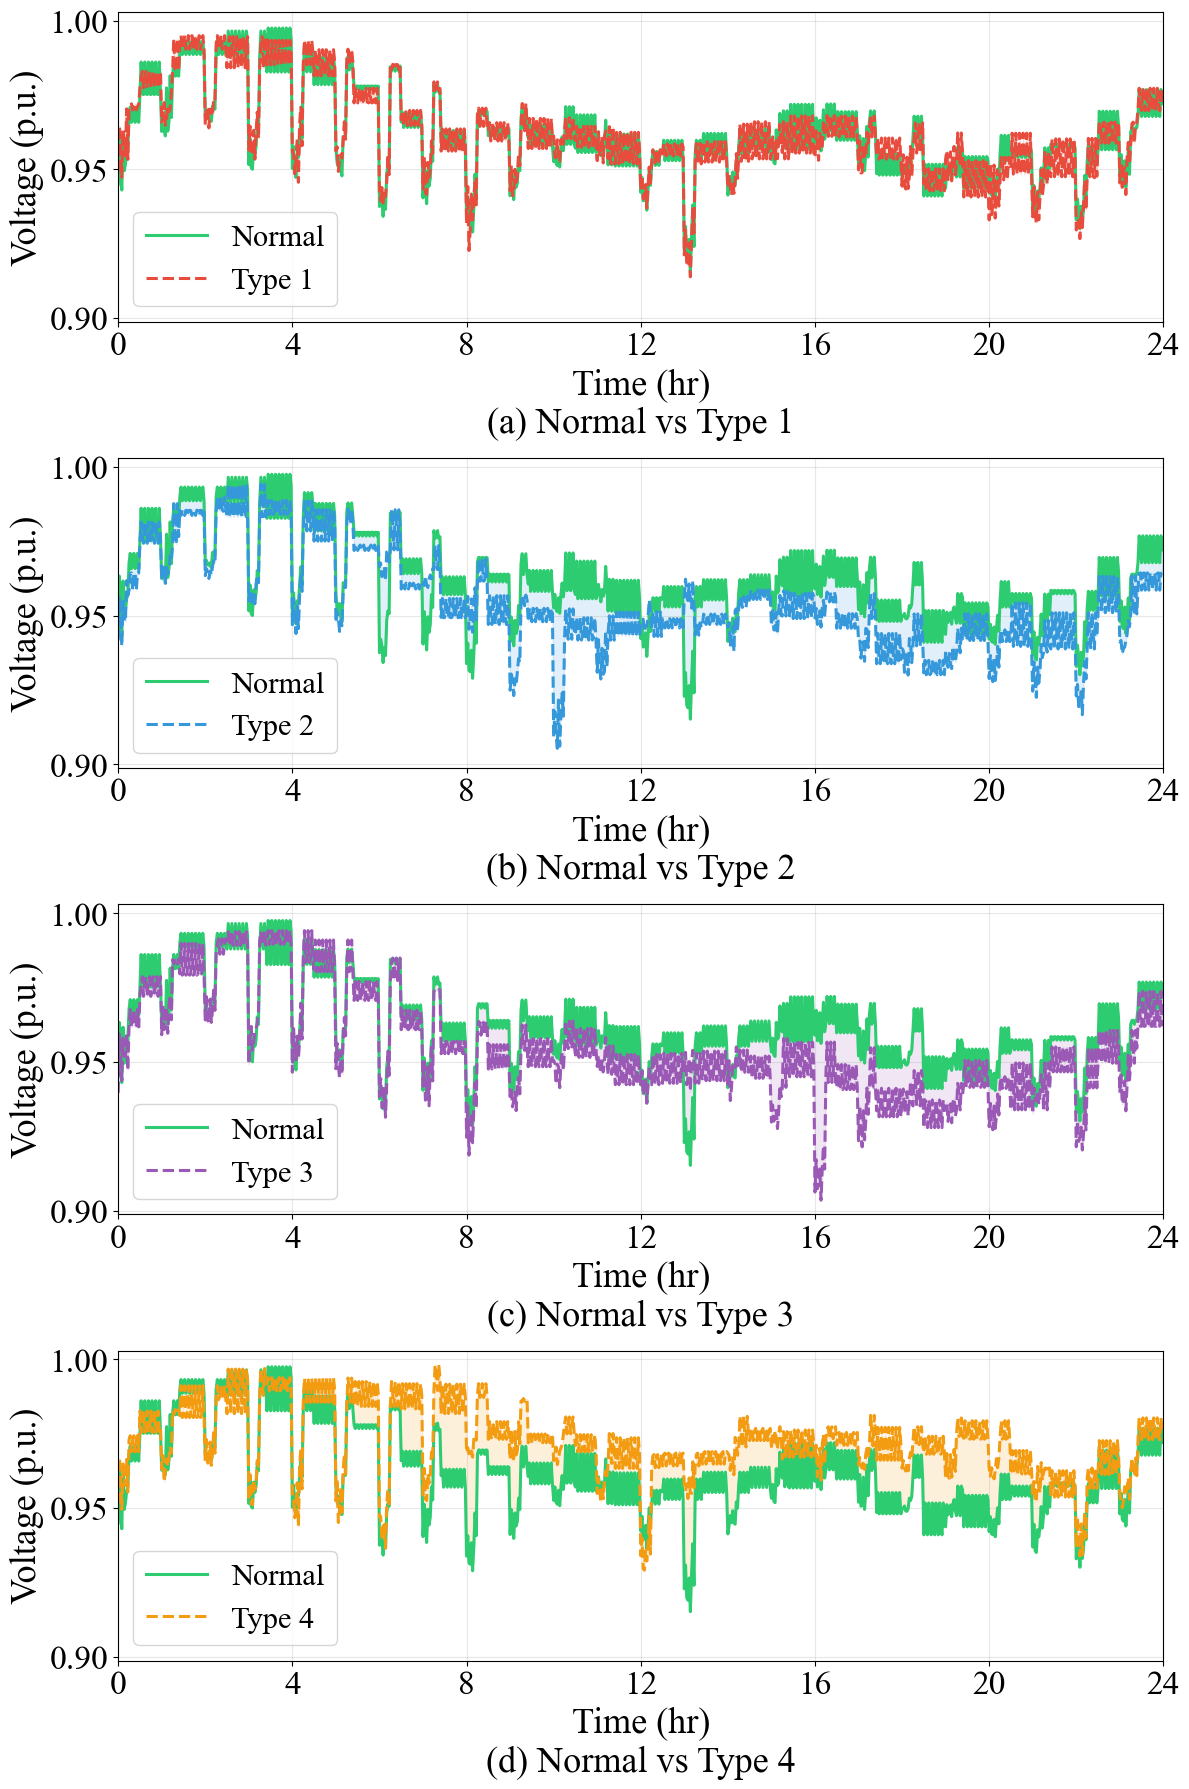

saved ITSG_voltage.pdf


In [4]:
with mpl.rc_context():                  # matplotlib defaults plus FIG23_RC, as these figures were drawn
    mpl.rcdefaults()
    mpl.rcParams.update(FIG23_RC)
    # unified y-limit across the four panels
    _vv = [to_1d(sources[a][k]['BusVoltage series'][sources[a]['bus']])
           for a in ATTACK_TYPES for k in ('nil', 'att')]
    vlo = min(v.min() for v in _vv)
    vhi = max(v.max() for v in _vv)
    vmar = (vhi - vlo) * 0.05

    fig, axes = plt.subplots(4, 1, figsize=(12, 18))
    for i, at in enumerate(ATTACK_TYPES):
        ax  = axes[i]
        src = sources[at]
        bus = src['bus']
        nv  = to_1d(src['nil']['BusVoltage series'][bus])
        av  = to_1d(src['att']['BusVoltage series'][bus])
        t   = hours_axis(len(nv))
        ax.plot(t, nv, color=COLORS['Normal'], lw=2.2, ls='-',  label='Normal')
        ax.plot(t, av, color=COLORS[at],       lw=2.2, ls='--', label=at)
        ax.fill_between(t, nv, av, color=COLORS[at], alpha=0.15)
        ax.set_xlabel('Time (hr)\n{} Normal vs {}'.format(SUBFIG_LABELS[i], at), fontsize=FS_LABEL)
        ax.set_ylabel('Voltage (p.u.)', fontsize=FS_LABEL)
        ax.set_xlim(0, DAY_HOURS)
        ax.set_ylim(vlo - vmar, vhi + vmar)
        ax.set_xticks(np.arange(0, DAY_HOURS + 1, 4))
        ax.legend(loc='lower left', fontsize=FS_LEGEND)
        ax.tick_params(labelsize=FS_TICK)
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUT / 'ITSG_voltage.pdf', bbox_inches='tight')
    plt.show()
    print('saved ITSG_voltage.pdf')

## Fig. 4: every method under full withdrawal

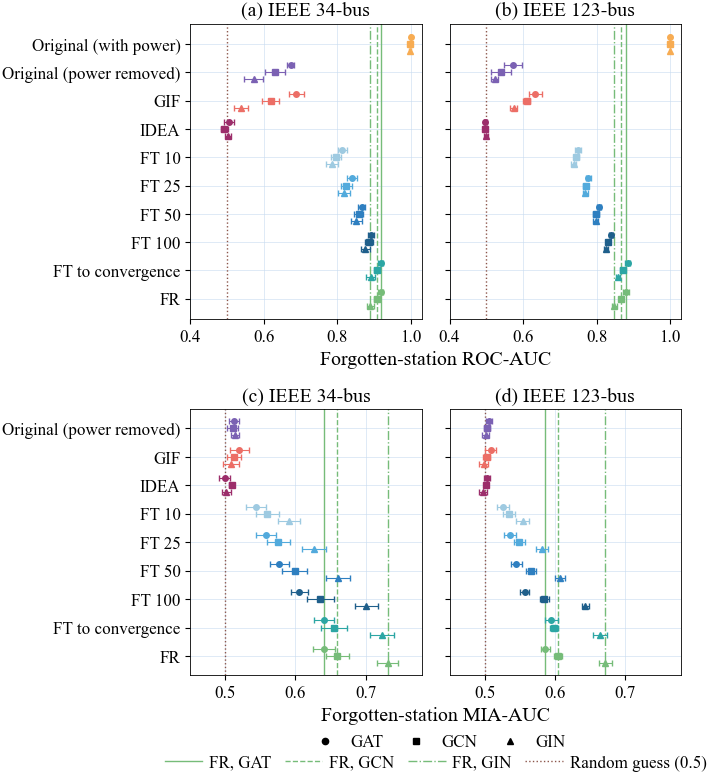

In [5]:
# Fig. 4: forgotten-station ROC-AUC (a)(b) and MIA-AUC (c)(d) of every method when every EVCS withdraws
fb = pd.read_csv(FIGB / 'figB_methods_trials.csv')
fm = pd.read_csv(TABLES / 'trials.csv')   # MIA-AUC of the same trials, frozen tables
FULL = {'34bus': 'S3', '123bus': 'S5'}
ROWS = ['Original_power', 'Mask_only', 'GIF', 'IDEA_cert', 'FT_e10', 'FT_e25', 'FT_e50', 'FT_e100',
        'WarmStart', 'Retrain']
# One marker, one FR line style and one vertical offset per backbone; the color stays that of the method
BACKBONES = (('GAT', 'o', '-', 0.25), ('GCN', 's', '--', 0.0), ('GIN', '^', '-.', -0.25))
# One row of panels per metric: column, trials, methods, x label, x range and ticks. The MIA is not computed for the
# original model, so its row leaves out Original (with power)
METRICS = (('ROC_forget', fb, ROWS, 'Forgotten-station ROC-AUC', (0.4, 1.03), [0.4, 0.6, 0.8, 1.0]),
           ('MIA_forget', fm, ROWS[1:], 'Forgotten-station MIA-AUC', (0.45, 0.78), [0.5, 0.6, 0.7]))


def mean_ci(x):
    return x.mean(), 1.96 * x.sem()


with fs.printed(fs.PAPER_SCALE):
    # (a)(b): every method on both feeders under full withdrawal, the method names on the left; one point per
    # backbone and one green FR line per backbone, since the floor differs between the backbones;
    # (c)(d): the MIA-AUC of the same methods
    # 0.4 in per method row, the pitch of the 21 rows in 8.4 in on 10/30; IDEA only at its certification noise,
    # so 19 rows
    fig, axes = plt.subplots(2, 2, figsize=(fs.DOUBLE, 0.4 * sum(len(m[2]) for m in METRICS)), sharey='row',
                             gridspec_kw=dict(height_ratios=[len(m[2]) for m in METRICS]))
    for row, (col, df, rows, xlabel, xlim, xticks) in zip(axes, METRICS):
        ypos = np.arange(len(rows))[::-1]
        for ax, bus in zip(row, FEEDERS):
            s = df[(df.feeder == bus) & (df.Scenario == FULL[bus])]
            for bb, mk, ls, dy in BACKBONES:
                sb = s[s.Backbone == bb]
                ax.axvline(sb[sb.method == 'Retrain'][col].mean(), color=fs.BAND, ls=ls, lw=1.0, zorder=2)
                for yi, m in zip(ypos, rows):
                    mu, h = mean_ci(sb[sb.method == m][col])
                    ax.errorbar(mu, yi + dy, xerr=h, color=fs.color(m), marker=mk, ms=4, ls='', zorder=3, **fs.ERR)
            # zorder 2 keeps the lines above the grid (1.5), which (c)(d) draw at 0.5 and 0.6
            ax.axvline(0.5, color=fs.RANDOM, ls=':', lw=1.0, zorder=2)
            ax.set_title(FEEDERS[bus])   # all stations withdrawn: in the caption
            ax.set_xlim(*xlim)
            ax.set_xticks(xticks)
        row[0].set_yticks(ypos)
        row[0].set_yticklabels([fs.name(m) for m in rows])
        row[0].set_xlabel(xlabel)
    fs.label_panels(axes)
    fig.tight_layout(w_pad=1.0)
    # One x label for the two panels of a row, moved to their middle once the layout is fixed; its height stays
    # automatic
    for row in axes:
        p0, p1 = row[0].get_position(), row[1].get_position()
        row[0].xaxis.label.set_x(((p0.x0 + p1.x1) / 2 - p0.x0) / p0.width)
    marker_handles = [Line2D([], [], color=KEY_COLOR, marker=mk, ls='', label=bb) for bb, mk, _, _ in BACKBONES]
    line_handles = [Line2D([], [], color=fs.BAND, ls=ls, lw=1.0, label=f'FR, {bb}') for bb, _, ls, _ in BACKBONES]
    line_handles.append(Line2D([], [], color=fs.RANDOM, ls=':', lw=1.0, label='Random guess (0.5)'))
    fs.legends_below(fig, [marker_handles, line_handles], handlelength=2.2)
    fig.savefig(OUT / 'Fig_B_floor_methods.pdf')
    plt.show()

## Fig. 5: voltage-only ROC-AUC against the electrical distance

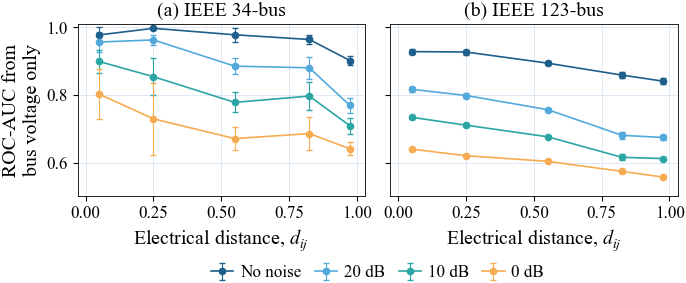

In [6]:
# Fig. 5: voltage-only ROC-AUC against the electrical distance from the EVCS, at four noise levels


def finish_pair(fig, axes, handles, name):
    """Panel letters, shared y axis, one legend below, saved to OUT."""
    plt.setp(axes[1].get_yticklabels(), visible=False)
    fs.label_panels(axes)
    fig.tight_layout(w_pad=1.0)
    fs.legends_below(fig, [handles])
    fig.savefig(OUT / name)
    plt.show()


with fs.printed(fs.PAPER_SCALE):
    fig, axes = plt.subplots(1, 2, figsize=(fs.DOUBLE, 2.9))
    for ax, f in zip(axes, FEEDERS):
        for snr, name, color in NOISE:
            x, m, ci = binned(at_snr(auc[auc.feeder == f], snr))
            ax.errorbar(x, m, yerr=ci, color=color, marker='o', label=name, **fs.ERR)
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylim(0.5, 1.01)
        ax.set_title(FEEDERS[f])
        ax.set_xlabel('Electrical distance, $d_{ij}$')           # from the station: in the caption
    axes[0].set_ylabel('ROC-AUC from\nbus voltage only')
    finish_pair(fig, axes, axes[0].get_legend_handles_labels()[0], 'Fig_A_floor_distance.pdf')

## Fig. 6: voltage-only ROC-AUC of each bus on the IEEE 34-bus feeder

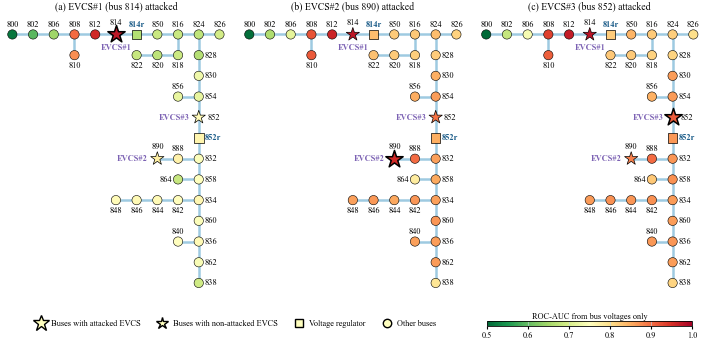

In [7]:
GRID_34 = {      # columns and rows of the feeder drawing in the framework figure
    'sourcebus': (-1, 0), '800': (0, 0), '802': (1, 0), '806': (2, 0), '808': (3, 0), '812': (4, 0),
    '814': (5, 0), '814r': (6, 0), '850': (7, 0), '816': (8, 0), '824': (9, 0), '826': (10, 0),
    '810': (3, -1), '818': (8, -1), '820': (7, -1), '822': (6, -1),
    '828': (9, -1), '830': (9, -2), '854': (9, -3), '852': (9, -4), '852r': (9, -5), '832': (9, -6),
    '858': (9, -7), '834': (9, -8), '860': (9, -9), '836': (9, -10), '862': (9, -11), '838': (9, -12),
    '856': (8, -3), '888': (8, -6), '890': (7, -6), '864': (8, -7),
    '842': (8, -8), '844': (7, -8), '846': (6, -8), '848': (5, -8), '840': (8, -10)}
LABEL_SIDE_34 = {b: 'right' for b in ('828', '830', '854', '852', '852r', '832', '858', '834', '860', '836',
                                      '862', '838')}
LABEL_SIDE_34.update({b: 'below' for b in ('sourcebus', '810', '818', '820', '822', '842', '844', '846', '848')})
LABEL_SIDE_34['864'] = 'left'
TAG_SIDE_34 = {'814': 'below', '852': 'left', '890': 'left'}       # EVCS#k tags, clear of the bus numbers
REG_SIDE_123 = {'160r': 'right'}                                    # 123-bus names kept apart at bus 62
TAG_SIDE_123 = {'62': 'left'}
SIDE = {'above': (0, 1, 'center', 'bottom'), 'below': (0, -1, 'center', 'top'),
        'right': (1, 0, 'left', 'center'), 'left': (-1, 0, 'right', 'center')}


def bus_xy(f, G):
    """Bus positions: the framework figure's grid for the 34-bus, the OpenDSS diagram for the 123-bus."""
    if f == '34bus':
        return {b: np.array(p, float) for b, p in GRID_34.items()}
    xy = pd.read_csv(DATA / 'ieee123_bus_xy.csv', dtype={'bus': str}).set_index('bus')
    pos = {b: xy.loc[b, ['x', 'y']].to_numpy(float) / 100 for b in xy.index}
    for stub, (bus, far) in {'94_open': ('54', '94'), '300_open': ('151', '300')}.items():
        step = pos[far] - pos[bus]
        axis = np.argmax(np.abs(step))                    # along the dominant direction of the open switch
        pos[stub] = pos[bus].copy()
        pos[stub][axis] += 1.5 * np.sign(step[axis])
    # The file puts each regulator's load side on its source bus; move it halfway to the next bus
    depth = nx.single_source_shortest_path_length(G, ROOT_BUS[f])
    for u, v, a in G.edges(data=True):
        if str(a.get('Label', '')).startswith('reg'):
            src, out = sorted((u, v), key=depth.get)
            if np.allclose(pos[src], pos[out]):
                nxt = next(n for n in G.neighbors(out) if n != src)
                pos[out] = (pos[src] + pos[nxt]) / 2
    assert set(pos) >= set(G), set(G) - set(pos)
    return pos


def draw_edges(ax, G, pos, lw):
    for u, v in G.edges():
        (x1, y1), (x2, y2) = pos[u], pos[v]
        xs, ys = ([x1, x2], [y1, y2]) if x1 == x2 or y1 == y2 else ([x1, x2, x2], [y1, y1, y2])  # elbow
        ax.plot(xs, ys, color='#9ECAE1', lw=lw, zorder=1, solid_capstyle='round')


def put(ax, p, side, gap, text, **kw):
    dx, dy, ha, va = SIDE[side]
    ax.text(p[0] + dx * gap, p[1] + dy * gap, text, ha=ha, va=va, zorder=5, **kw)


SIZE = {'34bus': {'bus': 45, 'reg': 48, 'evcs': 100, 'attacked': 170},
        '123bus': {'bus': 14, 'reg': 22, 'evcs': 58, 'attacked': 125}}


def draw_panel(ax, f, s, G, pos, regs, vals):
    """One map: every bus colored by its AUC for station s, stars for stations, squares for regulators."""
    sts, big = STATIONS[f], f == '123bus'
    gap = 1.3 if big else 0.3                            # label distance in grid units
    draw_edges(ax, G, pos, 1.0 if big else 1.8)
    kind = {b: 'attacked' if b == s else 'evcs' if b in sts else 'reg' if b in regs else 'bus' for b in G}
    for name, marker in (('bus', 'o'), ('reg', 's'), ('evcs', '*'), ('attacked', '*')):
        nodes = [b for b in G if kind[b] == name]
        if not nodes:
            continue
        xy = np.array([pos[b] for b in nodes])
        sc = ax.scatter(xy[:, 0], xy[:, 1], c=[vals[b] for b in nodes], cmap='RdYlGn_r', vmin=0.5, vmax=1.0,   # red: the voltage reveals the attack
                        s=SIZE[f][name], marker=marker, zorder=3 if name == 'bus' else 4,
                        edgecolors='black', linewidths={'attacked': 1.1, 'bus': 0.4}.get(name, 0.5))
    for b in G:
        evcs_tag = f'EVCS#{sts.index(b) + 1}' if b in sts else None
        if big:                                           # 123-bus: station tags below, regulator names above
            if evcs_tag:
                put(ax, pos[b], TAG_SIDE_123.get(b, 'below'), gap, evcs_tag, fontsize=fs.SMALL, color=EVCS_TEXT,
                    fontweight='bold')
            elif b in regs:
                put(ax, pos[b], REG_SIDE_123.get(b, 'above'), gap, b, fontsize=fs.SMALL, color=REG_TEXT, fontweight='bold')
            continue
        put(ax, pos[b], LABEL_SIDE_34.get(b, 'above'), gap + 0.1 * bool(evcs_tag), b, fontsize=fs.SMALL,
            color=REG_TEXT if b in regs else 'black', fontweight='bold' if b in regs else 'normal')
        if evcs_tag:
            put(ax, pos[b], TAG_SIDE_34[b], gap + 0.15, evcs_tag, fontsize=fs.SMALL, color=EVCS_TEXT, fontweight='bold')
    ax.set_aspect('equal')
    ax.margins(0.05)
    ax.axis('off')
    return sc


def map_legend(f):
    s = SIZE[f]
    ms = lambda area: np.sqrt(area) * 0.9                 # scatter area to legend marker size
    return [Line2D([0], [0], marker='*', ls='', markerfacecolor='#FFFFBF', markeredgecolor='black',
                   markersize=ms(s['attacked']), label='Buses with attacked EVCS'),
            Line2D([0], [0], marker='*', ls='', markerfacecolor='#FFFFBF', markeredgecolor='black',
                   markersize=ms(s['evcs']), label='Buses with non-attacked EVCS'),
            Line2D([0], [0], marker='s', ls='', markerfacecolor='#FFFFBF', markeredgecolor='black',
                   markersize=ms(s['reg']), label='Voltage regulator'),
            Line2D([0], [0], marker='o', ls='', markerfacecolor='#FFFFBF', markeredgecolor='black',
                   markersize=ms(s['bus']), label='Other buses')]


def setup(f, snr):
    G = nx.read_gml(GML[f])
    d = at_snr(auc[auc.feeder == f], snr)
    regs = regulator_outputs(G, ROOT_BUS[f])
    if f == '34bus':
        G.remove_node('sourcebus')       # drawn as in the framework figure: bus 800 is the source bus
    return G, bus_xy(f, G), regs, d


def draw_row(f, snr, name, height=3.45):
    """The paper version: every station of the feeder in one row, the legend in one line below and the colorbar
    beside it. No title and no noise level, which the caption gives."""
    G, pos, regs, d = setup(f, snr)
    sts = STATIONS[f]
    fig = plt.figure(figsize=(fs.DOUBLE, height))
    gs = fig.add_gridspec(2, len(sts), height_ratios=[1, 0.1], left=0.01, right=0.99, bottom=0.01, top=0.93,
                          hspace=0.08, wspace=0.04)
    axes = [fig.add_subplot(gs[0, k]) for k in range(len(sts))]
    for k, s in enumerate(sts):
        sc = draw_panel(axes[k], f, s, G, pos, regs, d[d.station_bus == s].set_index('bus').auc)
        axes[k].set_title(f'EVCS#{k + 1} (bus {s}) attacked', pad=9)       # clear of the bus numbers on the top row
    fs.label_panels(axes)
    keys = fig.add_subplot(gs[1, :-1])                   # legend under the first panels, colorbar under the last
    keys.axis('off')
    handles = map_legend(f)
    leg = keys.legend(handles=handles, loc='center', ncol=len(handles), columnspacing=1.5, handletextpad=0.3)
    cell = gs[1, -1].get_position(fig)
    cax = fig.add_axes([cell.x0 + 0.05 * cell.width, cell.y0, 0.9 * cell.width, 0.3 * cell.height])
    cb = fig.colorbar(sc, cax=cax, orientation='horizontal')
    cb.ax.xaxis.set_label_position('top')
    cb.set_label('ROC-AUC from bus voltages only', fontsize=fs.LEGEND, labelpad=1.5)
    cb.ax.tick_params(labelsize=fs.SMALL, pad=1.5, length=2.5)     # tight, so the bar keeps some thickness
    # The bar level with the legend markers, its label above and its ticks below
    fig.canvas.draw()
    inv = fig.transFigure.inverted()
    lo, hi = inv.transform(leg._legend_box.get_window_extent())[:, 1]
    thick = 0.4 * (hi - lo)
    cax.set_position([cax.get_position().x0, (lo + hi - thick) / 2, cax.get_position().width, thick])
    fig.savefig(OUT / name)
    plt.show()


with fs.printed():                                  # the paper fonts, at the printed size
    draw_row('34bus', 20, 'E9_topology_34bus_20dB.pdf')

## Fig. 7: voltage-only ROC-AUC of each bus on the IEEE 123-bus feeder

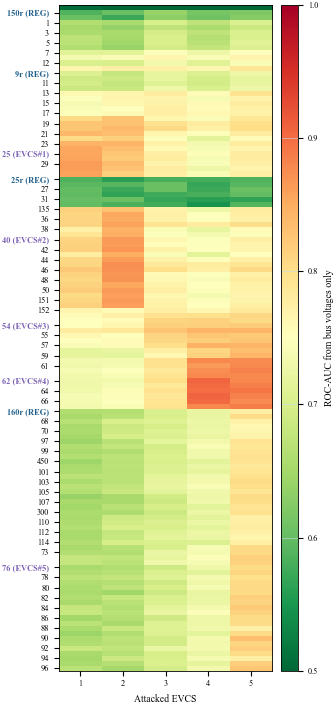

In [8]:
def feeder_order(G, root):
    """Buses in the order of the feeder drawing: depth first from the substation, the smaller branch first."""
    T = nx.bfs_tree(G, root)
    size = {n: len(nx.descendants(T, n)) for n in T}
    order = []

    def visit(n):
        order.append(n)
        for m in sorted(T.successors(n), key=size.get):
            visit(m)
    visit(root)
    return order


def label_rows(order, marked, step):
    """Rows that get a bus name: every marked bus, the others at least `step` rows apart."""
    rows = []
    for i, b in enumerate(order):
        if b in marked:
            if rows and i - rows[-1] < step and order[rows[-1]] not in marked:
                rows.pop()
            rows.append(i)
        elif (not rows or i - rows[-1] >= step) and not set(order[i + 1:i + step]) & marked:
            rows.append(i)
    return rows


def draw_heatmap(snr, name, feeders=tuple(FEEDERS), paper=False):
    """One panel per feeder. paper=True leaves out the titles and the noise level, which the caption gives."""
    one = len(feeders) == 1
    fig, axes = plt.subplots(1, len(feeders) + 1, figsize=(fs.SINGLE, 7.2) if one else (fs.DOUBLE, 8.6),
                             gridspec_kw={'width_ratios': [len(STATIONS[f]) for f in feeders] + [0.4 if one else 0.22]})
    for ax, f in zip(axes[:-1], feeders):
        G = nx.read_gml(GML[f])
        d = at_snr(auc[auc.feeder == f], snr)
        mat = d.pivot_table(index='bus', columns='station_bus', values='auc')[STATIONS[f]]
        order = [b for b in feeder_order(G, ROOT_BUS[f]) if b in mat.index]
        im = ax.imshow(mat.loc[order].values, aspect='auto', cmap='RdYlGn_r', vmin=0.5, vmax=1.0,
                       interpolation='nearest')
        ax.set_xticks(range(len(STATIONS[f])))
        if paper:                                         # one column per attacked EVCS, named under the numbers
            ax.set_xticklabels([str(k + 1) for k in range(len(STATIONS[f]))])
            ax.set_xlabel('Attacked EVCS')
        else:
            ax.set_xticklabels([f'EVCS#{k + 1}' for k in range(len(STATIONS[f]))], rotation=45, ha='right',
                               rotation_mode='anchor')
        evcs = {s: k + 1 for k, s in enumerate(STATIONS[f])}
        regs = regulator_outputs(G, ROOT_BUS[f])
        step = 1 if len(order) <= 40 else 2              # every second bus on the 123-bus, so the names stay legible
        rows = label_rows(order, set(evcs) | regs, step)
        ax.set_yticks(rows)
        ax.set_yticklabels([f'{order[i]} (EVCS#{evcs[order[i]]})' if order[i] in evcs else
                            f'{order[i]} (REG)' if order[i] in regs else order[i] for i in rows],
                           fontsize=fs.TICK if step == 1 else fs.SMALL)
        for lab, i in zip(ax.get_yticklabels(), rows):
            if order[i] in evcs or order[i] in regs:
                lab.set_color(EVCS_TEXT if order[i] in evcs else REG_TEXT)
                lab.set_fontweight('bold')
        if not paper:
            ax.set_title(FEEDERS[f])
        ax.grid(False)
        cb = fig.colorbar(im, cax=axes[-1])                # as tall as the heatmaps
    cb.set_label('ROC-AUC from bus voltages only' if paper else
                 f'ROC-AUC from bus voltage only, {"no noise" if snr is None else f"{snr} dB"}')
    if not one:
        fs.label_panels(axes[:-1])
    fig.tight_layout()
    fig.savefig(OUT / name)
    plt.show()


with fs.printed():                                  # the paper fonts, at the printed size
    draw_heatmap(20, 'E9_heatmap_123bus_20dB.pdf', feeders=('123bus',), paper=True)

## Fig. 8: attack types not seen in training

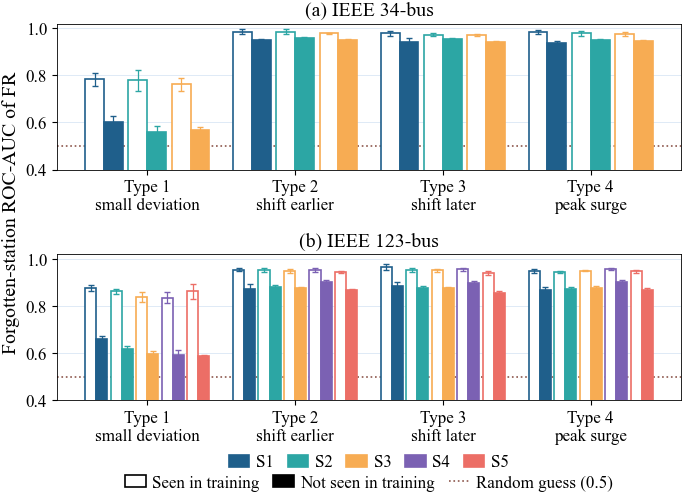

In [9]:
holdout = pd.read_csv(RE / 'e10_holdout.csv', dtype={'type': str})
# Fig. 8: forgotten-station ROC-AUC of FR for each attack type, seen or not seen in training
TYPES = ['1', '2', '3', '4']
TYPE_NAMES = {'1': 'Type 1\nsmall deviation', '2': 'Type 2\nshift earlier', '3': 'Type 3\nshift later',
              '4': 'Type 4\npeak surge'}
h = holdout[(holdout.method == 'Retrain') & holdout['type'].isin(TYPES)]
feeders = [f for f in fs.FEEDER if f in set(h.feeder)]
scens_all = sorted(h[h.training == 'held out'].Scenario.unique())
H = 2.4 * len(feeders)                      # lowered on 10/23 for the main text
with fs.printed(fs.PAPER_SCALE):
    fig, axes = plt.subplots(len(feeders), 1, figsize=(fs.DOUBLE, H), squeeze=False)
    for ax, bus in zip(axes[:, 0], feeders):
        hb = h[h.feeder == bus]
        scens = sorted(hb[hb.training == 'held out'].Scenario.unique())
        n = len(scens)
        w = 0.84 / (2 * n + 0.3 * (n - 1))     # pairs of bars, a small gap between the pairs
        for s, scen in enumerate(scens):
            color = fs.SCENARIO[scen]
            center = (s - (n - 1) / 2) * 2.3 * w
            for training, dx, face in (('seen', -0.5, 'white'), ('held out', 0.5, color)):
                g = hb[(hb.Scenario == scen) & (hb.training == training)].groupby('type').ROC_forget.agg(
                    ['mean', 'std']).reindex(TYPES)
                ax.bar(np.arange(len(TYPES)) + center + dx * w, g['mean'], width=w, yerr=g['std'], facecolor=face,
                       edgecolor=color, linewidth=1.2, capsize=2.5, error_kw=dict(lw=0.9, ecolor=color), zorder=3)
        ax.axhline(0.5, color=fs.RANDOM, ls=':', lw=1.2, zorder=2)
        ax.set_xticks(range(len(TYPES)))
        ax.set_xticklabels([TYPE_NAMES[t] for t in TYPES])
        ax.set_ylim(0.4, 1.02)
        ax.grid(axis='x', visible=False)
        ax.set_axisbelow(True)
        if len(feeders) > 1:
            ax.set_title(fs.FEEDER[bus])
    if len(feeders) > 1:
        fs.label_panels(axes)
    top, bottom = axes[0, 0], axes[-1, 0]
    top.set_ylabel('Forgotten-station ROC-AUC of FR')    # one label for all rows
    fig.tight_layout()
    fig.canvas.draw()
    box, lab = top.get_window_extent(), top.yaxis.label.get_window_extent()
    middle = (bottom.get_position().y0 + top.get_position().y1) / 2
    top.yaxis.set_label_coords((lab.x1 - box.x0) / box.width,
                               (middle - top.get_position().y0) / top.get_position().height)
    # Two compact legend rows below the panels: color is the scenario, hollow or filled the training
    scen_handles = [Patch(facecolor=fs.SCENARIO[s], edgecolor=fs.SCENARIO[s], lw=1.2, label=s) for s in scens_all]
    style_handles = [Patch(facecolor='white', edgecolor=KEY_COLOR, lw=1.2, label='Seen in training'),
                     Patch(facecolor=KEY_COLOR, edgecolor=KEY_COLOR, lw=1.2, label='Not seen in training'),
                     Line2D([], [], color=fs.RANDOM, ls=':', lw=1.2, label='Random guess (0.5)')]
    fs.legends_below(fig, [scen_handles, style_handles], handlelength=1.2)
    fig.savefig(OUT / 'E10_holdout.pdf')
    plt.show()

## Fig. 9: sequential requests

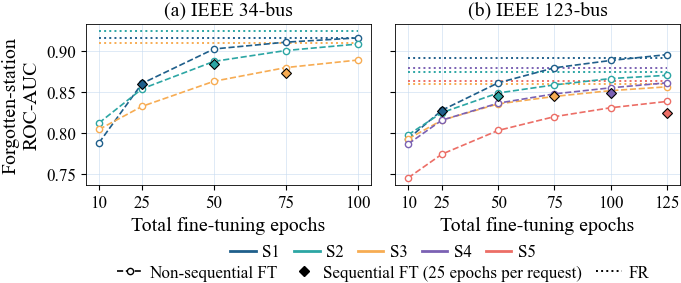

In [10]:
# Fig. 9: forgotten-station ROC-AUC against the total fine-tuning epochs, non-sequential FT (lines), sequential FT
# (diamonds) and FR of each step (dotted)
matched = pd.read_csv(RE / 'e4_matched.csv')
STEP_COLORS = {j: fs.SCENARIO[f'S{j}'] for j in range(1, 6)}
rows_raw = [('ROC_forget', 'Forgotten-station ROC-AUC'), ('MIA_forget', 'Forgotten-station MIA-AUC')]
step_handles = [Line2D([], [], color=STEP_COLORS[j], lw=2.0, label=f'S{j}') for j in sorted(matched.step.unique())]
style_raw = [Line2D([], [], color=KEY_COLOR, ls='--', marker='o', mfc='white', label='Non-sequential FT'),
             Line2D([], [], color=KEY_COLOR, marker='D', ms=5, ls='none', label='Sequential FT (25 epochs per request)'),
             Line2D([], [], color=KEY_COLOR, ls=':', lw=1.4, label=fs.name('Retrain'))]
with fs.printed(fs.PAPER_SCALE):
    fig, axes = plt.subplots(1, 2, figsize=(fs.DOUBLE, 2.7), sharey=True)
    col, ylabel = rows_raw[0]
    for ax, bus in zip(axes, ('34bus', '123bus')):
        d = matched[matched.feeder == bus]
        xmax = 125 if bus == '123bus' else 100
        for j in sorted(d.step.unique()):
            fr = d[(d['mode'] == 'fr') & (d.step == j)][col].mean()
            ax.plot([10, xmax], [fr, fr], ls=':', lw=1.4, color=STEP_COLORS[j], zorder=2)
            o = d[(d['mode'] == 'one-shot') & (d.step == j)].groupby('epochs')[col].mean()
            ax.plot(o.index, o.values, ls='--', marker='o', mfc='white', color=STEP_COLORS[j], zorder=3)
            q = d[(d['mode'] == 'sequential') & (d.step == j)]
            ax.plot(q.epochs.iloc[0], q[col].mean(), marker='D', ms=5, color=STEP_COLORS[j],   # smaller on 10/27
                    mec=KEY_COLOR, mew=0.8, ls='none', zorder=4)
        ax.set_title(fs.FEEDER[bus])
        ax.set_xlabel('Total fine-tuning epochs')
        ax.set_xticks([10, 25, 50, 75, 100, 125] if bus == '123bus' else [10, 25, 50, 75, 100])
    axes[0].set_ylabel(ylabel.replace(' ROC', '\nROC'))
    fs.label_panels(axes)
    fig.tight_layout()
    fs.legends_below(fig, [step_handles, style_raw], handlelength=1.5)
    fig.savefig(OUT / 'E4_matched_epochs_raw_roc.pdf')
    plt.show()